# FoodHub: Exploratory Analysis of Food-Delivery Orders

Author: Mersedyes Livingston

Problem summary, data description, results and re-analysis: see [README.md](README.md).

> Built on a course-provided template. Course instructions and problem text were removed with `tools/clean_notebook.py`; code, outputs and observations are unchanged. Data is not redistributed, so cells that load it will not run as-is.


In [1]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 -q --user

In [2]:
# Import libraries for data manipulation
import numpy as np
import pandas as pd

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [3]:
# uncomment and run the following lines for Google Colab
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Read the data
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/foodhub_order.csv') ## Fill the blank to read the data

In [5]:
# Returns the first 5 rows
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data?

In [6]:
# Check the shape of the dataset
rows, columns = df.shape ## Fill in the blank
print(f"There are {rows} and {columns} columns")

There are 1898 and 9 columns


### **Question 2:** What are the datatypes of the different columns in the dataset?

In [7]:
df.info()
# print(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


# Observations Summary:

•	The columns order_id, customer_id, food_preparation_time, and delivery_time are of type int64.

•	The cost_of_the_order is of type float64.

•	The restaurant_name, cuisine_type, day_of_the_week, and rating are of type object (basically strings).


### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method.

In [8]:
# Checking for missing values in the data
#Write the appropriate function to print the sum of null values for each column

# detect missing values by looking at the count
df.describe()
df.isnull().sum()

#Result: all False results
df.isnull().any()

# total number for the dataframe
df.isnull().sum().sum() #Result is 0

# Check for NA results
df.isna().sum() #Result is 0

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed?

In [9]:
# Get the summary statistics of the numerical data
summary = df.describe() ## Write the appropriate function to print the statitical summary of the data (Hint - you have seen this in the case studies before)
print(summary)

           order_id    customer_id  cost_of_the_order  food_preparation_time  \
count  1.898000e+03    1898.000000        1898.000000            1898.000000   
mean   1.477496e+06  171168.478398          16.498851              27.371970   
std    5.480497e+02  113698.139743           7.483812               4.632481   
min    1.476547e+06    1311.000000           4.470000              20.000000   
25%    1.477021e+06   77787.750000          12.080000              23.000000   
50%    1.477496e+06  128600.000000          14.140000              27.000000   
75%    1.477970e+06  270525.000000          22.297500              31.000000   
max    1.478444e+06  405334.000000          35.410000              35.000000   

       delivery_time  
count    1898.000000  
mean       24.161749  
std         4.972637  
min        15.000000  
25%        20.000000  
50%        25.000000  
75%        28.000000  
max        33.000000  


### **Observations** on Food Preparation Time
1. **Minimum Food Preparation Time**:
   - The minimum value is **20 minutes**, meaning that the quickest preparation time for an order is 20 minutes.

2. **Average (Mean) Food Preparation Time**:
   - The average (mean) preparation time is **27.37 minutes**. This suggests that, on average, it takes around 27 minutes to prepare food after an order is placed.

3. **Maximum Food Preparation Time**:
   - The maximum food preparation time is **35 minutes**, indicating that the longest preparation time for an order is 35 minutes.

4. **Standard Deviation**:
   - The standard deviation is **4.63 minutes**, which shows some variability in food preparation times around the mean. This means the times are somewhat spread out, but most fall within 4-5 minutes of the average.


### Conclusion:
The food preparation time generally ranges from 20 minutes to 35 minutes, with the average being around 27 minutes. The standard deviation shows some variation in preparation times, but they stay within a reasonably consistent range.

### **Question 5:** How many orders are not rated?

In [10]:
# What are the rating types?
rating_type = df.rating.unique()
print(f"The rating types are: {rating_type}\n")

not_rated = df['rating'].value_counts()['Not given']
print(f"There are {not_rated} orders not rated.\n")

# What is the count of each rating?
rating_count = df['rating'].value_counts()
print(rating_count)

The rating types are: ['Not given' '5' '3' '4']

There are 736 orders not rated.

Not given    736
5            588
4            386
3            188
Name: rating, dtype: int64


### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.)

#### Order ID

In [11]:
# check unique order ID
df['order_id'].nunique()

1898

#### Customer ID

In [12]:
# check unique customer ID
df['customer_id'].nunique()

1200

#### Restaurant name

In [13]:
# check unique Restaurant Name
df['restaurant_name'].nunique()

178

#### Cuisine type

In [14]:
# Check unique cuisine type
df['cuisine_type'].nunique()

14

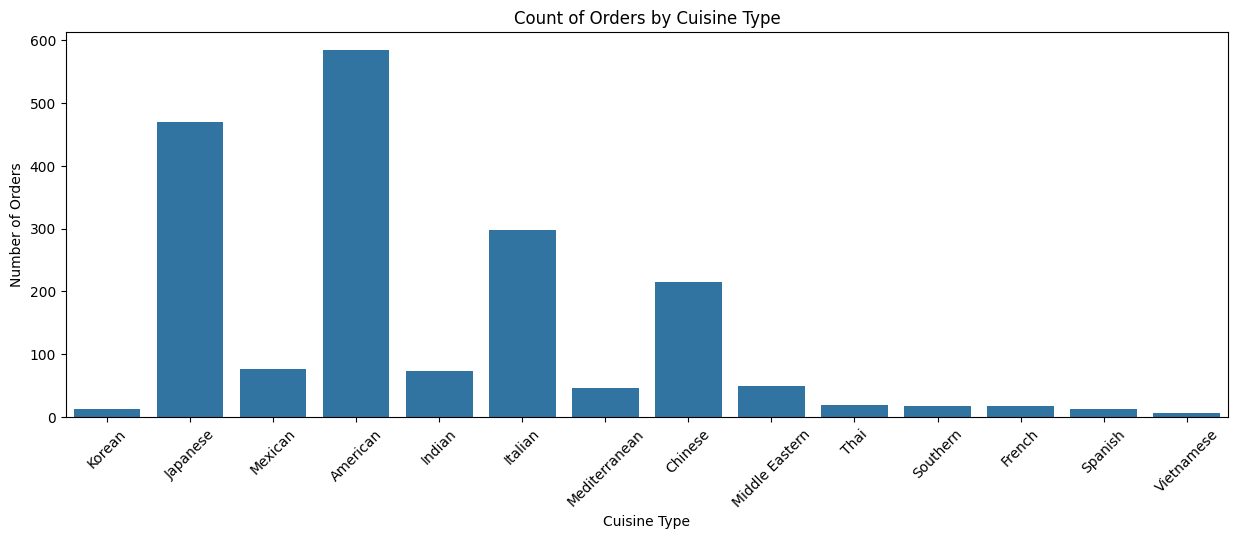

In [15]:
plt.figure(figsize = (15,5))
sns.countplot(data = df, x = 'cuisine_type') ## Create a countplot for cuisine type.
plt.title('Count of Orders by Cuisine Type')
plt.xlabel('Cuisine Type')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.show()

#### Cost of the order

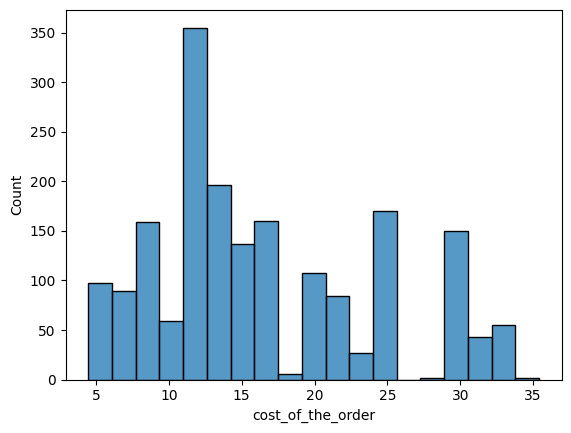

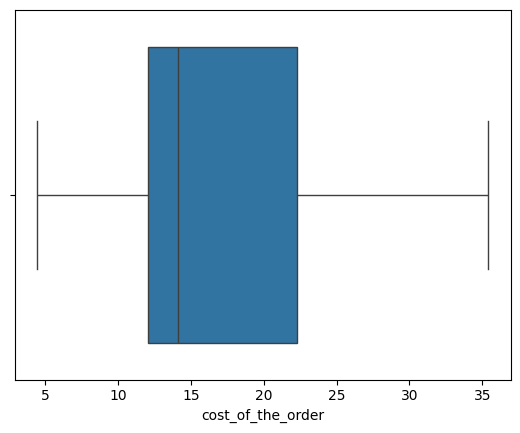

In [16]:
sns.histplot(data=df,x='cost_of_the_order') ## Histogram for the cost of order
plt.show()
sns.boxplot(data=df,x='cost_of_the_order') ## Boxplot for the cost of order
plt.show()

#### Day of the week

In [17]:
# # Check the unique values
df['day_of_the_week'].unique()
print(df['day_of_the_week'].unique())

['Weekend' 'Weekday']


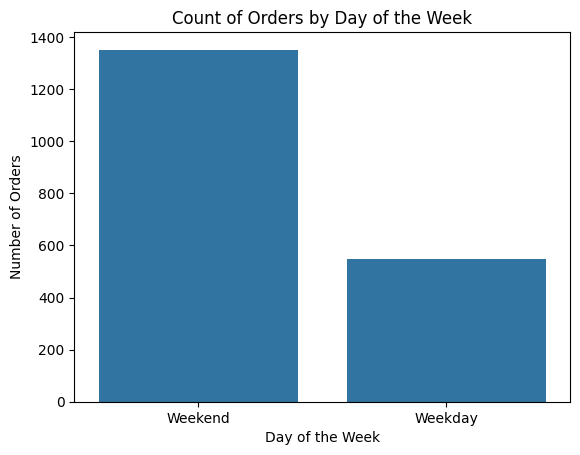

In [18]:
sns.countplot(data = df, x = 'day_of_the_week')

plt.title('Count of Orders by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Orders')
plt.show()

#### Rating

In [19]:
# Check the unique values
df['rating'].unique()

array(['Not given', '5', '3', '4'], dtype=object)

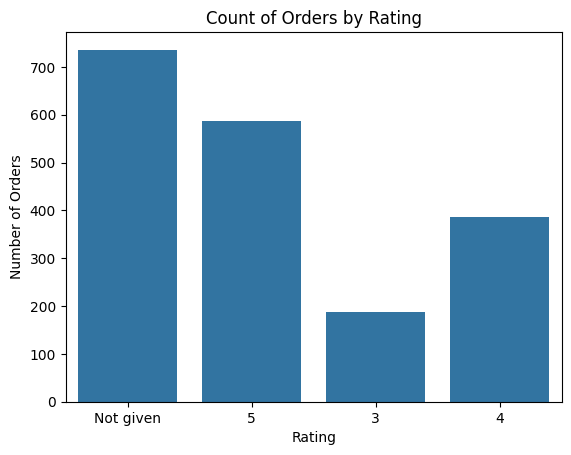

In [20]:
sns.countplot(data = df, x = 'rating')

plt.title('Count of Orders by Rating')
plt.xlabel('Rating')
plt.ylabel('Number of Orders')
plt.show()

#### Food Preparation time

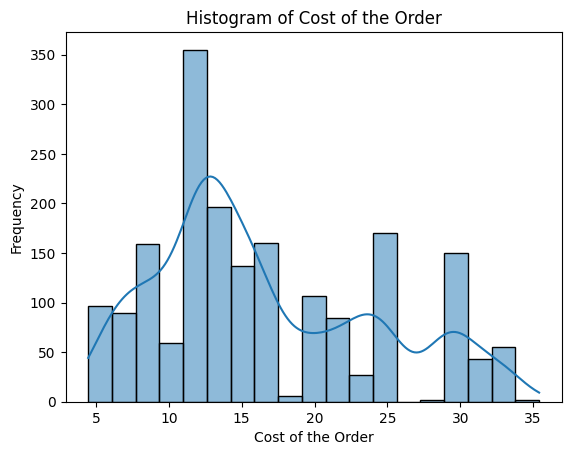

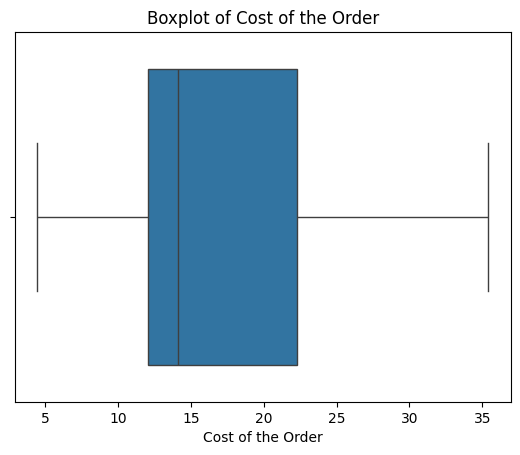

In [21]:
sns.histplot(data=df,x='cost_of_the_order', kde=True)
plt.title('Histogram of Cost of the Order')
plt.xlabel('Cost of the Order')
plt.ylabel('Frequency')
plt.show()

sns.boxplot(data=df,x='cost_of_the_order')
plt.title('Boxplot of Cost of the Order')
plt.xlabel('Cost of the Order')
plt.show()

#### Delivery time

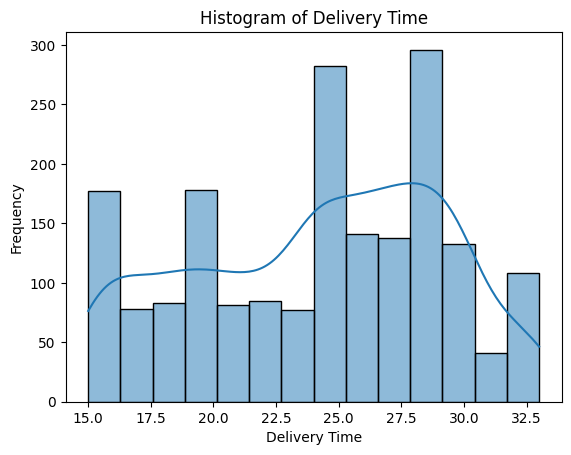

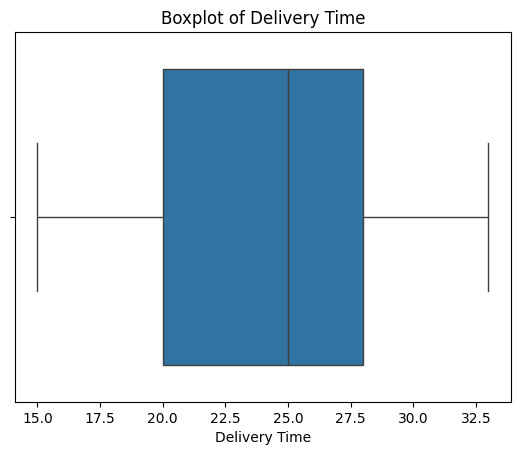

In [22]:
sns.histplot(data=df,x='delivery_time', kde=True)
plt.title('Histogram of Delivery Time')
plt.xlabel('Delivery Time')
plt.ylabel('Frequency')
plt.show()

sns.boxplot(data=df,x='delivery_time')
plt.title('Boxplot of Delivery Time')
plt.xlabel('Delivery Time')
plt.show()

### **Question 7:** Which are the top 5 restaurants in terms of the number of orders received?

In [23]:
# Get top 5 restaurants with highest number of orders
df['restaurant_name'].value_counts().head(5)

,restaurant_name
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


### **Question 8:** Which is the most popular cuisine on weekends?

In [24]:
# Get most popular cuisine on weekends
df_weekend = df[df['day_of_the_week'] == 'Weekend']
df_weekend['cuisine_type'].value_counts()

,cuisine_type
American,415
Japanese,335
Italian,207
Chinese,163
Mexican,53
Indian,49
Mediterranean,32
Middle Eastern,32
Thai,15
French,13


### **Question 9:** What percentage of the orders cost more than 20 dollars?


In [25]:
# Get orders that cost above 20 dollars
df_greater_than_20 = df[df['cost_of_the_order']>20] ## Write the appropriate column name to get the orders having cost above $20

# Calculate the number of total orders where the cost is above 20 dollars
print('The number of total orders that cost above 20 dollars is:', df_greater_than_20.shape[0])

# Calculate percentage of such orders in the dataset
percentage = (df_greater_than_20.shape[0] / df.shape[0]) * 100

print("Percentage of orders above 20 dollars:", round(percentage, 2), '%')

The number of total orders that cost above 20 dollars is: 555
Percentage of orders above 20 dollars: 29.24 %


### **Question 10:** What is the mean order delivery time?

In [26]:
# Get the mean delivery time
mean_del_time = df['delivery_time'].mean()  ## Write the appropriate function to obtain the mean delivery time

print('The mean delivery time for this dataset is', round(mean_del_time, 2), 'minutes')

The mean delivery time for this dataset is 24.16 minutes


### **Question 11:** The company has decided to give 20% discount vouchers to the top 5 most frequent customers. Find the IDs of these customers and the number of orders they placed.

In [27]:
# Get the counts of  each customer_id
df['customer_id'].value_counts().head(3)  ## Write the appropriate column name to get the top 5 cmost frequent customers

,customer_id
52832,13
47440,10
83287,9


### Multivariate Analysis

### **Question 12:** Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables)

#### Cuisine vs Cost of the order

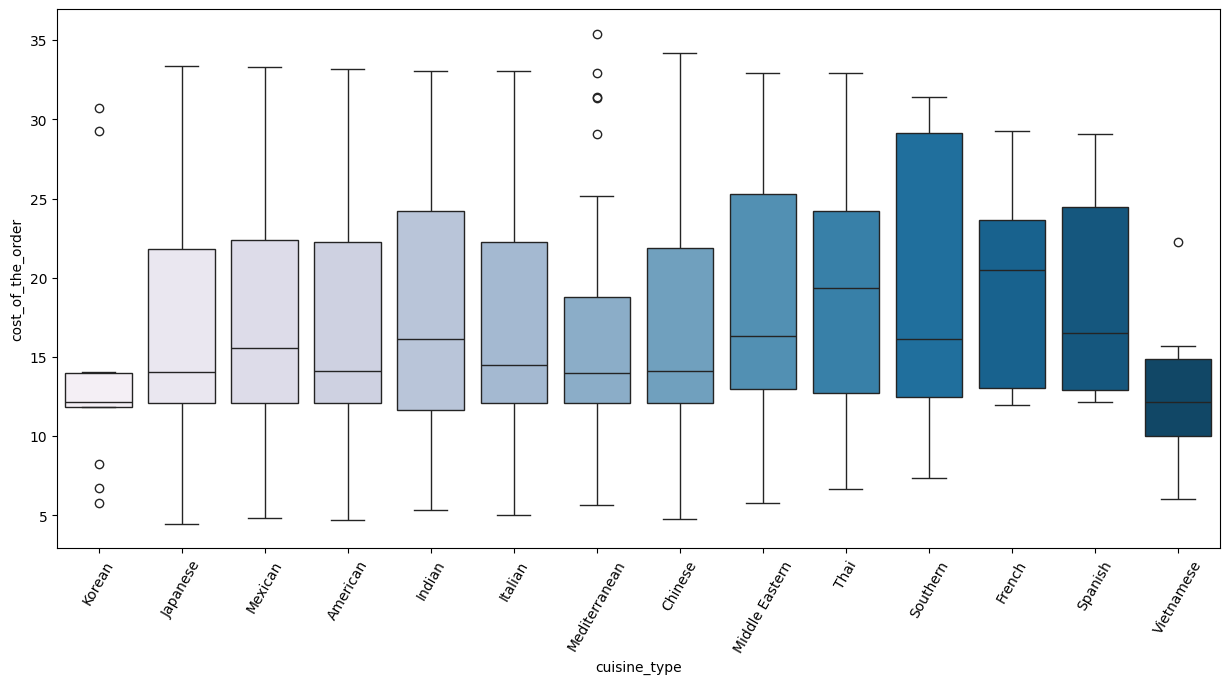

In [28]:
# Relationship between cost of the order and cuisine type
plt.figure(figsize=(15,7))
sns.boxplot(x = "cuisine_type", y = "cost_of_the_order", data = df, palette = 'PuBu', hue = "cuisine_type")
plt.xticks(rotation = 60)
plt.show()

#### Cuisine vs Food Preparation time

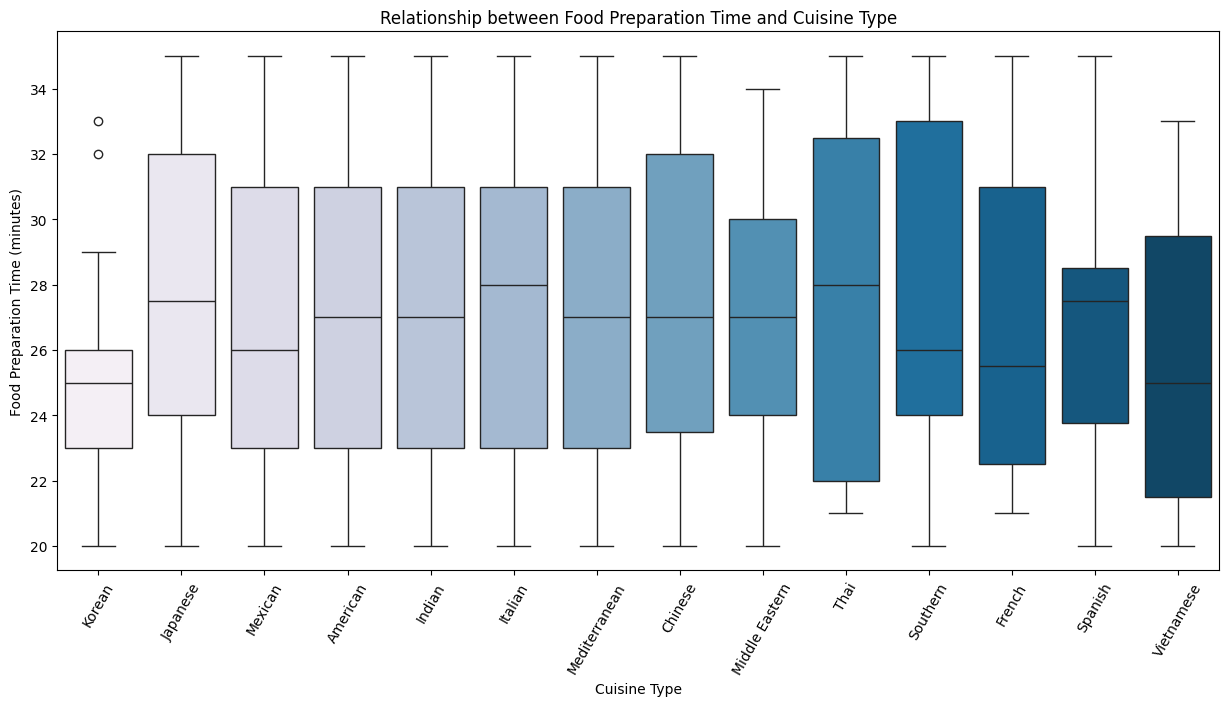

In [42]:
# Relationship between food preparation time and cuisine type
plt.figure(figsize=(15,7))
sns.boxplot(data=df, x='cuisine_type', y='food_preparation_time', palette = 'PuBu', hue = "cuisine_type")
plt.xticks(rotation = 60)
plt.title('Relationship between Food Preparation Time and Cuisine Type')
plt.xlabel('Cuisine Type')
plt.ylabel('Food Preparation Time (minutes)')
plt.show()

#### Day of the Week vs Delivery time

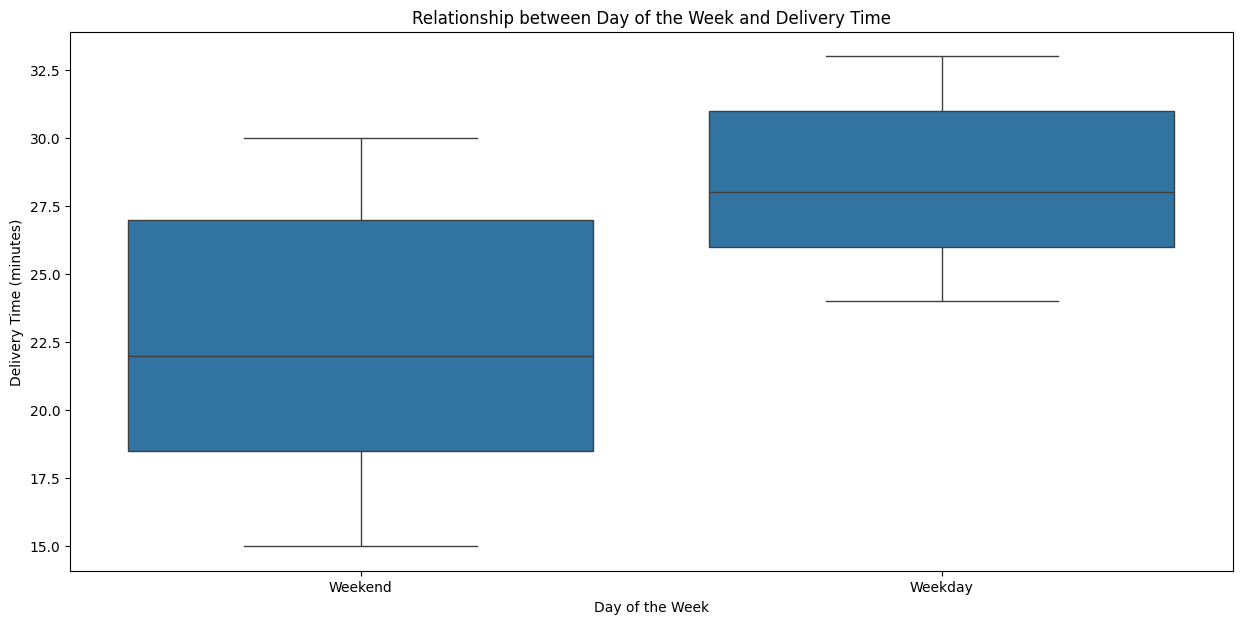

In [44]:
# Relationship between day of the week and delivery time
plt.figure(figsize=(15,7))
sns.boxplot(data=df, x='day_of_the_week', y='delivery_time')
plt.title('Relationship between Day of the Week and Delivery Time')
plt.xlabel('Day of the Week')
plt.ylabel('Delivery Time (minutes)')
plt.show()

#### Run the below code and write your observations on the revenue generated by the restaurants.

In [31]:
df.groupby(['restaurant_name'])['cost_of_the_order'].sum().sort_values(ascending = False).head(14)

,cost_of_the_order
restaurant_name,
Shake Shack,3579.53
The Meatball Shop,2145.21
Blue Ribbon Sushi,1903.95
Blue Ribbon Fried Chicken,1662.29
Parm,1112.76
RedFarm Broadway,965.13
RedFarm Hudson,921.21
TAO,834.50
Han Dynasty,755.29


### Observations on the Revenue Generated by the Restaurants

1. **Top Performers**  
   Shake Shack leads by a significant margin with $3579.53 in total revenue, followed by The Meatball Shop with $2145.21 and Blue Ribbon Sushi with $1903.95.  
   These three restaurants generate significantly more revenue compared to the others, indicating they are the highest-performing in terms of total order costs.

2. **Revenue Distribution**  
   After the top three, the revenue starts to drop off, with Blue Ribbon Fried Chicken at $1662.29 and Parm at $1112.76.  
   The gap in revenue between the top restaurants and those lower in the list is quite large. For example, RedFarm Broadway at $965.13 has much lower revenue than The Meatball Shop ($2145.21).

3. **Lower Revenue Restaurants**  
   Restaurants like Five Guys Burgers and Fries generate much less revenue with only $506.47, indicating they have fewer or lower-cost orders compared to the top performers.

4. **Diversity in Cuisine**  
   The list includes a variety of restaurant types, ranging from fast-casual (e.g., Shake Shack and Five Guys) to higher-end dining options (e.g., Blue Ribbon Sushi and Nobu Next Door). This shows that the dataset includes both casual and more upscale establishments.

5. **Order Volume Insights**  
   Restaurants at the top of the list (such as Shake Shack) likely have a higher volume of orders, whereas those at the bottom (e.g., Five Guys) could be attracting fewer customers or have a lower average order value.

### Conclusion  
   **Shake Shack** stands out as a major contributor to the total revenue, followed by a few others in the $1000-$2000 range. The rest of the restaurants show relatively smaller contributions.  
   This suggests a **concentration of revenue** in a few high-performing restaurants, with others contributing significantly less.

#### Rating vs Delivery time

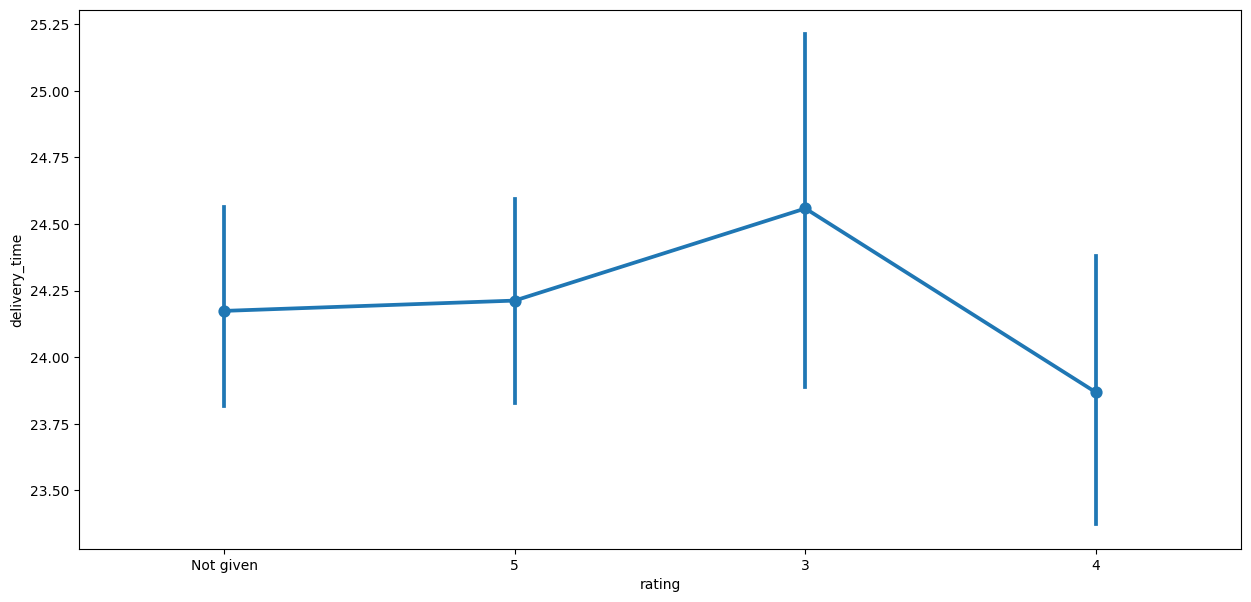

In [32]:
# Relationship between rating and delivery time
plt.figure(figsize=(15, 7))
sns.pointplot(x = 'rating', y = 'delivery_time', data = df)
plt.show()

#### Rating vs Food preparation time

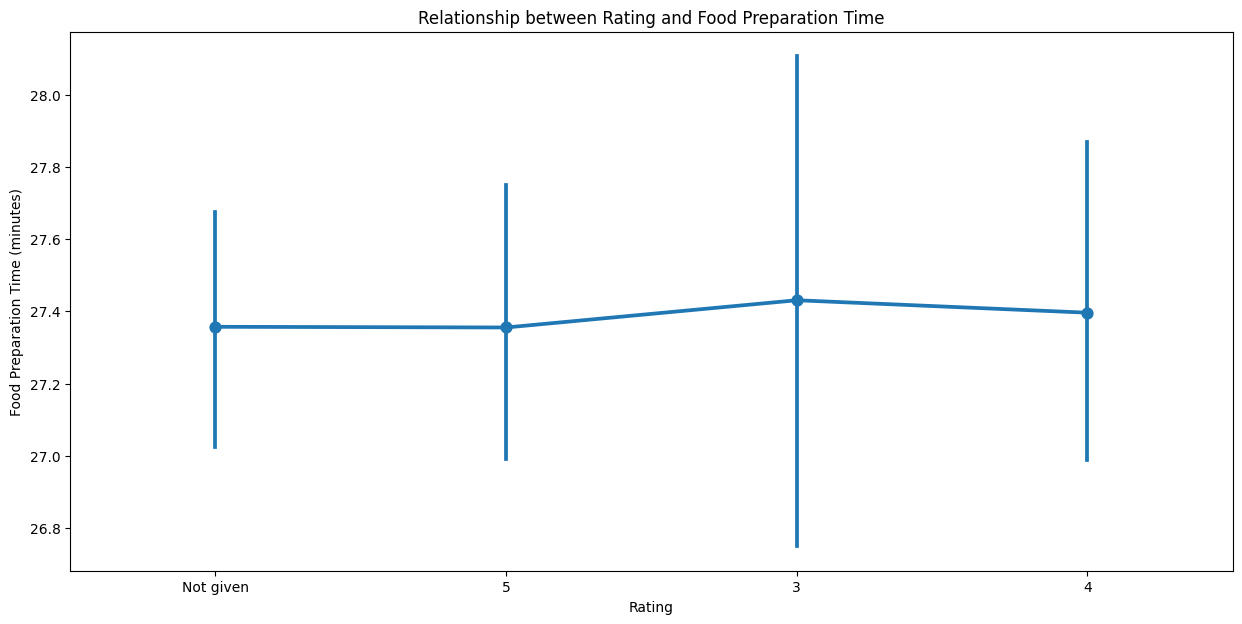

In [45]:
# Relationship between rating and food preparation time
plt.figure(figsize=(15, 7))
sns.pointplot(data=df, x='rating', y='food_preparation_time', markers='o', linestyles='-')
plt.title('Relationship between Rating and Food Preparation Time')
plt.xlabel('Rating')
plt.ylabel('Food Preparation Time (minutes)')
plt.show()

#### Rating vs Cost of the order

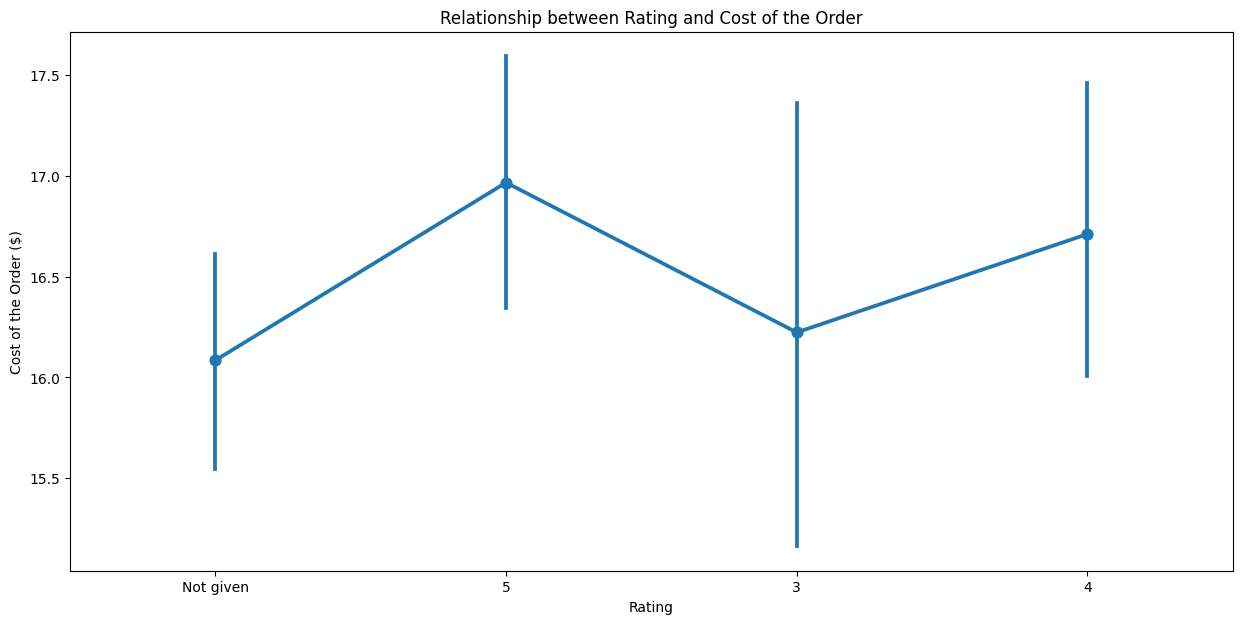

In [46]:
# Relationship between rating and cost of the order
plt.figure(figsize=(15, 7))
sns.pointplot(data=df, x='rating', y='cost_of_the_order', markers='o', linestyles='-')
plt.title('Relationship between Rating and Cost of the Order')
plt.xlabel('Rating')
plt.ylabel('Cost of the Order ($)')
plt.show()

#### Correlation among variables

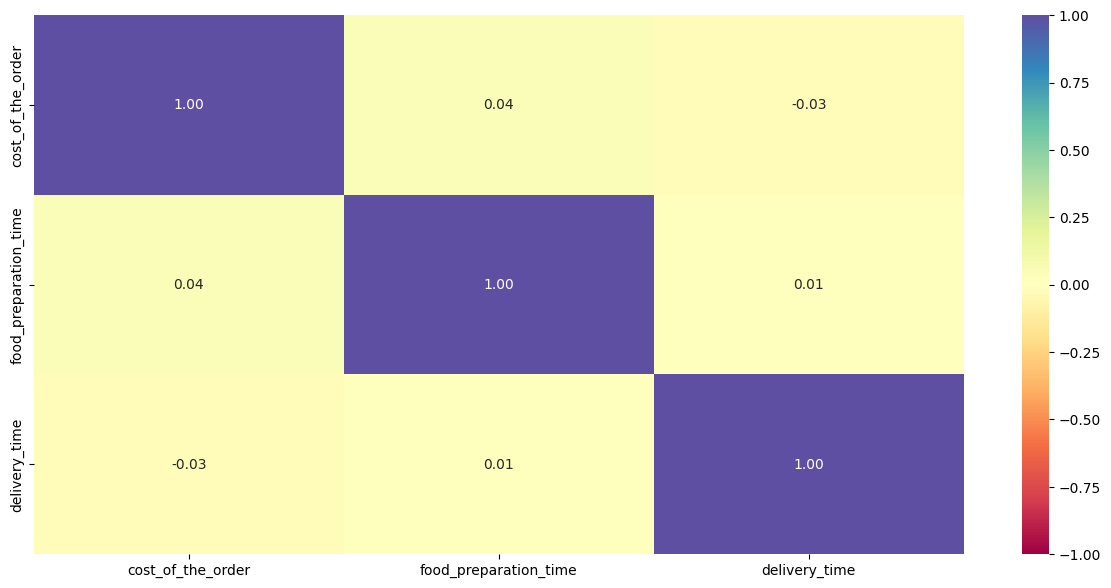

In [35]:
# Plot the heatmap
col_list = ['cost_of_the_order', 'food_preparation_time', 'delivery_time']
plt.figure(figsize=(15, 7))
sns.heatmap(df[col_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer.

In [36]:
# Filter the rated restaurants
df_rated = df[df['rating'] != 'Not given'].copy()

# Convert rating column from object to integer
df_rated['rating'] = df_rated['rating'].astype('int')

# Create a dataframe that contains the restaurant names with their rating counts
df_rating_count = df_rated.groupby(['restaurant_name'])['rating'].count().sort_values(ascending = False).reset_index()
df_rating_count.head()

,restaurant_name,rating
0,Shake Shack,133
1,The Meatball Shop,84
2,Blue Ribbon Sushi,73
3,Blue Ribbon Fried Chicken,64
4,RedFarm Broadway,41


In [37]:
# Get the restaurant names that have rating count more than 50
rest_names = df_rating_count[df_rating_count['rating'] > 50]['restaurant_name']

# Filter to get the data of restaurants that have rating count more than 50
df_mean_4 = df_rated[df_rated['restaurant_name'].isin(rest_names)].copy()

# Group the restaurant names with their ratings and find the mean rating of each restaurant
df_mean_4_rating = df_mean_4.groupby(['restaurant_name'])['rating'].mean().sort_values(ascending = False).reset_index().dropna()

# filter for average rating greater than 4
df_avg_rating_greater_than_4 = df_mean_4_rating[df_mean_4_rating['rating'] > 4].sort_values(by='rating', ascending=False).reset_index(drop=True)

df_avg_rating_greater_than_4

,restaurant_name,rating
0,The Meatball Shop,4.511905
1,Blue Ribbon Fried Chicken,4.328125
2,Shake Shack,4.278195
3,Blue Ribbon Sushi,4.219178


### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders.

In [38]:
#function to determine the revenue
def compute_rev(x):
    if x > 20:
        return x*0.25
    elif x > 5:
        return x*0.15
    else:
        return x*0

df['Revenue'] = df['cost_of_the_order'].apply(compute_rev) ## Write the apprpriate column name to compute the revenue
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time,Revenue
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20,7.6875
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23,1.8120
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28,1.8345
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15,7.3000
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24,1.7385


In [39]:
# get the total revenue and print it
total_rev = df['Revenue'].sum() ## Write the appropriate function to get the total revenue
print('The net revenue is around', round(total_rev, 2), 'dollars')

The net revenue is around 6166.3 dollars


### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.)


In [40]:
# Calculate total delivery time and add a new column to the dataframe df to store the total delivery time
df['total_time'] = df['food_preparation_time'] + df['delivery_time']


## Write the code below to find the percentage of orders that have more than 60 minutes of total delivery time (see Question 9 for reference)
orders_over_60 = df[df['total_time'] > 60].shape[0]
total_orders = df.shape[0]
percentage_over_60 = (orders_over_60 / total_orders) * 100

print(f"The percentage of orders that take more than 60 minutes to deliver is: {round(percentage_over_60, 2)}%")




The percentage of orders that take more than 60 minutes to deliver is: 10.54%


### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends?

> Add blockquote



In [41]:
# Get the mean delivery time on weekdays and print it
print('The mean delivery time on weekdays is around',
      round(df[df['day_of_the_week'] == 'Weekday']['delivery_time'].mean()),
     'minutes')


## Write the code below to get the mean delivery time on weekends and print it
print('The mean delivery time on weekends is around',
      round(df[df['day_of_the_week'] == 'Weekend']['delivery_time'].mean()),
     'minutes')

The mean delivery time on weekdays is around 28 minutes
The mean delivery time on weekends is around 22 minutes


### Conclusion and Recommendations


### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.)

### Conclusions:
*  

### Recommendations:

*  